# **TUGAS MEMBUAT RECIPE**
### **NAMA : HERMITA LESTARI**
### **NIM : H061241062**


Jumlah record : 365
Rentang waktu : 2025-01-01 s.d. 2025-12-31
                 item  nilai
               record 365.00
 tanggal_hilang (gap)   0.00
        nilai_missing   0.00
     tanggal_duplikat   0.00
di_luar_rentang_wajar   0.00
              T2M_min  25.66
              T2M_max  29.44
             T2M_mean  27.52
              T2M_std   0.74

Ringkasan bulanan:
         T2M_mean  T2M_min  T2M_max  T2M_std  n_hari
date                                                
2025-01     26.77    25.92    27.75     0.48      31
2025-02     26.98    26.19    27.63     0.40      28
2025-03     27.50    26.07    28.45     0.51      31
2025-04     27.64    26.56    28.42     0.47      30
2025-05     28.24    26.97    28.84     0.34      31
2025-06     27.29    26.37    28.08     0.57      30
2025-07     26.91    25.66    27.89     0.60      31
2025-08     27.38    26.60    27.75     0.31      31
2025-09     28.37    27.12    29.35     0.54      30
2025-10     28.56    27.16    29.44     0.56

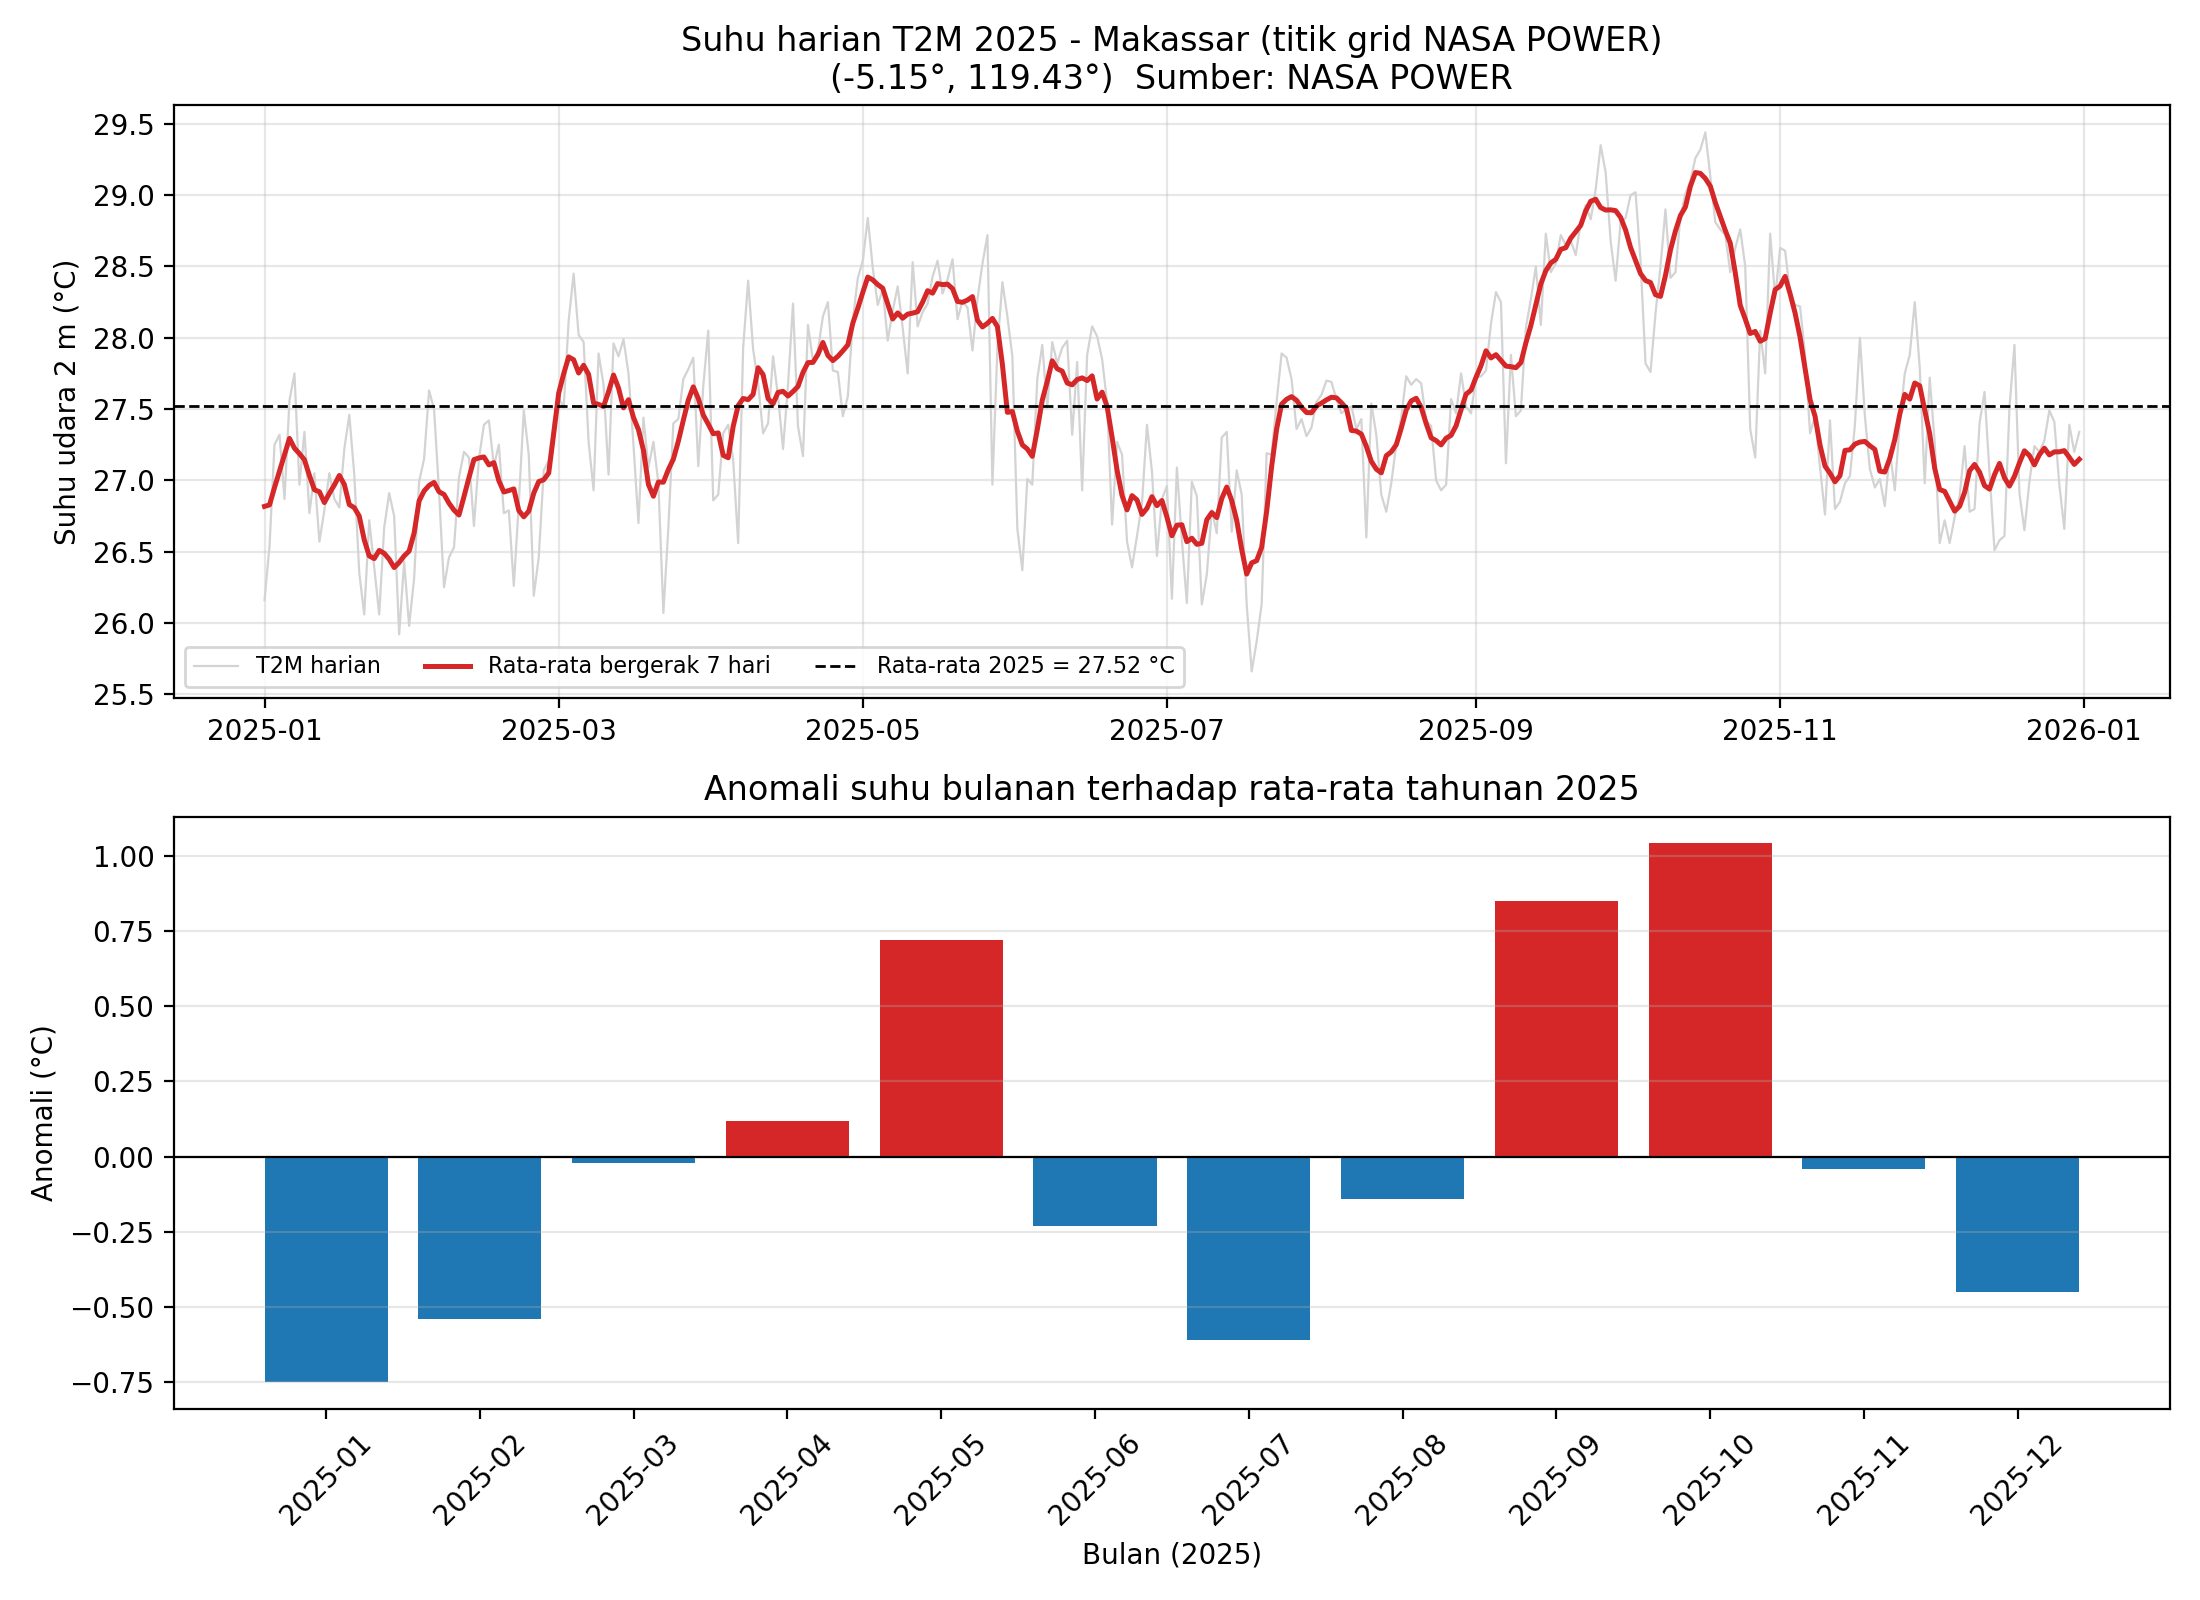


Selesai. Lihat folder: C:\Users\Thinkpad\Downloads\outputs_suhu


In [4]:
import os, json, hashlib, sys, subprocess
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

#
INPUT_CSV = Path.home() / "Downloads" / "POWER_Point_Daily_20250101_20251231_005d15S_119d43E_LST.csv"
OUT_DIR   = Path.home() / "Downloads" / "outputs_suhu"
LAT, LON  = -5.15, 119.43          
NAMA_LOKASI = "Makassar (titik grid NASA POWER)"
T_MIN_WAJAR, T_MAX_WAJAR = 10.0, 45.0   
JENDELA_RATA_BERGERAK = 7               
NODATA = -999                          
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 500)  



def tampilkan_grafik(path_png):
    """Di notebook (Jupyter/VS Code/Colab): tampilkan PNG inline.
    Di luar notebook: buka file PNG dengan aplikasi bawaan OS."""
    path_png = Path(path_png)

    

    try:
        from IPython import get_ipython
        from IPython.display import Image, display
        if get_ipython() is not None:
            display(Image(filename=str(path_png)))
            return
    except ImportError:
        pass
 
   
    if matplotlib.get_backend().lower() not in ("agg", "pdf", "svg", "ps", "cairo", "template"):
        plt.show()
        return
 
    
    try:
        if sys.platform.startswith("win"):
            os.startfile(path_png)
        elif sys.platform == "darwin":
            subprocess.run(["open", str(path_png)], check=False)
        else:
            subprocess.run(["xdg-open", str(path_png)], check=False)
    except Exception as e:
        print(f"Gagal membuka otomatis ({e}). Buka manual: {path_png}")
 


df = pd.read_csv(INPUT_CSV)
df["date"] = pd.to_datetime(dict(year=df["YEAR"], month=df["MO"], day=df["DY"]))
df = df.sort_values("date").set_index("date")
df["T2M"] = df["T2M"].replace(NODATA, np.nan)
print("Jumlah record :", len(df))
print("Rentang waktu :", df.index.min().date(), "s.d.", df.index.max().date())


tanggal_lengkap = pd.date_range(df.index.min(), df.index.max(), freq="D")
tanggal_hilang = tanggal_lengkap.difference(df.index)
n_missing = int(df["T2M"].isna().sum())
n_duplikat = int(df.index.duplicated().sum())
n_di_luar = int(((df["T2M"] < T_MIN_WAJAR) | (df["T2M"] > T_MAX_WAJAR)).sum())

qc = pd.DataFrame({
    "item": ["record", "tanggal_hilang (gap)", "nilai_missing", "tanggal_duplikat",
             "di_luar_rentang_wajar", "T2M_min", "T2M_max", "T2M_mean", "T2M_std"],
    "nilai": [len(df), len(tanggal_hilang), n_missing, n_duplikat, n_di_luar,
              round(df["T2M"].min(), 2), round(df["T2M"].max(), 2),
              round(df["T2M"].mean(), 2), round(df["T2M"].std(), 2)],
})
qc.to_csv(OUT_DIR / "qc_summary.csv", index=False)
print(qc.to_string(index=False))


df = df.reindex(tanggal_lengkap)   
df.index.name = "date"
bulanan = df["T2M"].resample("MS").agg(["mean", "min", "max", "std", "count"]).round(2)
bulanan.index = bulanan.index.strftime("%Y-%m")
bulanan.columns = ["T2M_mean", "T2M_min", "T2M_max", "T2M_std", "n_hari"]
bulanan.to_csv(OUT_DIR / "suhu_bulanan.csv")
print("\nRingkasan bulanan:")
print(bulanan.to_string())


baseline = df["T2M"].mean()
df["anomali"] = df["T2M"] - baseline
df["rolling"] = df["T2M"].rolling(JENDELA_RATA_BERGERAK, center=True, min_periods=4).mean()
df[["T2M", "rolling", "anomali"]].round(2).to_csv(OUT_DIR / "suhu_harian_anomali.csv")

anom_bulanan = (bulanan["T2M_mean"] - baseline).round(2)
anom_bulanan.to_csv(OUT_DIR / "anomali_bulanan.csv", header=["anomali_vs_rata2_2025"])


fig, ax = plt.subplots(2, 1, figsize=(11, 8))

ax[0].plot(df.index, df["T2M"], color="lightgray", lw=0.8, label="T2M harian")
ax[0].plot(df.index, df["rolling"], color="tab:red", lw=1.8,
           label=f"Rata-rata bergerak {JENDELA_RATA_BERGERAK} hari")
ax[0].axhline(baseline, color="k", ls="--", lw=1, label=f"Rata-rata 2025 = {baseline:.2f} °C")
ax[0].set_ylabel("Suhu udara 2 m (°C)")
ax[0].set_title(f"Suhu harian T2M 2025 - {NAMA_LOKASI}\n({LAT}°, {LON}°)  Sumber: NASA POWER")
ax[0].legend(loc="lower left", ncol=3, fontsize=8)
ax[0].grid(alpha=0.3)

warna = ["tab:red" if v > 0 else "tab:blue" for v in anom_bulanan.values]
ax[1].bar(anom_bulanan.index, anom_bulanan.values, color=warna)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_ylabel("Anomali (°C)")
ax[1].set_xlabel("Bulan (2025)")
ax[1].set_title("Anomali suhu bulanan terhadap rata-rata tahunan 2025")
ax[1].tick_params(axis="x", rotation=45)
ax[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
PNG_PATH = OUT_DIR / "suhu_timeseries_anomali.png"
fig.savefig(PNG_PATH, dpi=200)
plt.close(fig)                    
tampilkan_grafik(PNG_PATH)        


geojson = {
    "type": "FeatureCollection",
    "features": [{
        "type": "Feature",
        "geometry": {"type": "Point", "coordinates": [LON, LAT]},
        "properties": {
            "nama": NAMA_LOKASI,
            "T2M_mean_2025": round(float(baseline), 2),
            "T2M_max_2025": round(float(df["T2M"].max()), 2),
            "T2M_min_2025": round(float(df["T2M"].min()), 2),
            "sumber": "NASA POWER daily point, T2M, LST",
            "crs": "EPSG:4326",
        },
    }],
}
with open(OUT_DIR / "lokasi_suhu.geojson", "w", encoding="utf-8") as f:
    json.dump(geojson, f, indent=2, ensure_ascii=False)


with open(INPUT_CSV, "rb") as f:
    sha = hashlib.sha256(f.read()).hexdigest()
bulan_panas = bulanan["T2M_mean"].idxmax()
bulan_dingin = bulanan["T2M_mean"].idxmin()
with open(OUT_DIR / "manifest.md", "w", encoding="utf-8") as f:
    f.write("# Result Manifest - R-USR-001\n\n")
    f.write(f"- Dibuat      : {datetime.now():%Y-%m-%d %H:%M}\n")
    f.write(f"- Input       : `{INPUT_CSV.name}`\n- SHA-256     : `{sha}`\n")
    f.write(f"- Lokasi      : {LAT}, {LON} (EPSG:4326)\n")
    f.write("- Sumber      : NASA POWER daily point, parameter T2M, waktu LST\n")
    f.write(f"- Record      : {len(df)} hari, missing = {n_missing}, gap = {len(tanggal_hilang)}\n")
    f.write(f"- Rata-rata   : {baseline:.2f} °C\n")
    f.write(f"- Bulan terpanas : {bulan_panas} ({bulanan.loc[bulan_panas, 'T2M_mean']} °C)\n")
    f.write(f"- Bulan terdingin: {bulan_dingin} ({bulanan.loc[bulan_dingin, 'T2M_mean']} °C)\n\n")
    f.write("## Batas interpretasi\n")
    f.write("- Data grid reanalisis/satelit (NASA POWER), bukan pengukuran stasiun.\n")
    f.write("- Hanya 1 tahun: anomali dihitung terhadap rata-rata 2025, bukan klimatologi multi-tahun.\n")
    f.write("- Hasil tidak boleh dibaca sebagai bukti perubahan iklim.\n\n")
    f.write("## Output\n")
    for nama in sorted(os.listdir(OUT_DIR)):
        f.write(f"- {nama}\n")

print("\nSelesai. Lihat folder:", OUT_DIR)